In [2]:
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')
np.random.seed(42)

REPO_ROOT  = Path('..').resolve()
DATA_DIR   = REPO_ROOT / 'data' / 'judge step'
OUT_TABLES = REPO_ROOT / 'outputs' / 'tables'
OUT_FIGS   = REPO_ROOT / 'outputs' / 'figures'
OUT_TABLES.mkdir(parents=True, exist_ok=True)
OUT_FIGS.mkdir(parents=True, exist_ok=True)

PROVIDERS        = ['openai', 'gemini', 'qwen']
VALID_LABELS     = {'ABSTAIN', 'CORRECT', 'INCORRECT'}
DIFFICULTY_ORDER  = ['easy', 'medium', 'hard']
DIFFICULTY_LABELS = {'easy': 'Easy', 'medium': 'Medium', 'hard': 'Hard'}

MODEL_MAP = {
    'claude_sonnet4':       ('claude-sonnet-4',        'frontier'),
    'gemini31_flash_lite':  ('gemini-3.1-flash-lite',  'frontier'),
    'gpt54mini':            ('gpt-5.4-mini',           'frontier'),
    'qwen36':               ('qwen3.6:27b',            'open'),
    'gemma4':               ('gemma4:26b',             'open'),
    'qwen3.6:27b':          ('qwen3.6:27b',            'open'),
    'gemma4_26b':           ('gemma4:26b',             'open'),
}
MODEL_ORDER = [
    'gpt-5.4-mini', 'gemma4:26b', 'qwen3.6:27b',
    'claude-sonnet-4', 'gemini-3.1-flash-lite',
]
MODEL_SHORT = {
    'gpt-5.4-mini':           'GPT-5.4-mini',
    'gemma4:26b':             'Gemma4 26B',
    'qwen3.6:27b':            'Qwen3.6 27B',
    'claude-sonnet-4':        'Claude Son. 4.5',
    'gemini-3.1-flash-lite':  'Gemini 3.1 FL',
}

# ── Model colors: Wong 2011; solid=frontier, dashed=open ─────────────────────
MODEL_COLORS = {
    'gpt-5.4-mini':           '#0072B2',
    'gemma4:26b':             '#E69F00',
    'qwen3.6:27b':            '#009E73',
    'claude-sonnet-4':        '#CC79A7',
    'gemini-3.1-flash-lite':  '#D55E00',
}
DISPLAY_LS = {
    'gpt-5.4-mini':          '-',
    'gemini-3.1-flash-lite': '-',
    'claude-sonnet-4':       '-',
    'gemma4:26b':            '--',
    'qwen3.6:27b':           '--',
}
MARKER_SHAPES = {
    'gpt-5.4-mini':           'o',
    'gemini-3.1-flash-lite':  's',
    'claude-sonnet-4':        'D',
    'gemma4:26b':             '^',
    'qwen3.6:27b':            'v',
}

# ── Label colors sampled from the same cmaps used in the heatmaps ─────────────
LABEL_COLORS = {
    'ABSTAIN':   mcolors.to_hex(plt.cm.Blues(0.65)),
    'INCORRECT': mcolors.to_hex(plt.cm.Oranges(0.65)),
    'CORRECT':   mcolors.to_hex(plt.cm.Greens(0.65)),
}

# Computed after tbl_main is built (Rate Tables cell)
ABSTAIN_YLIM,   ABSTAIN_YTICKS   = (0, 100), list(range(0, 101, 10))
INCORRECT_YLIM, INCORRECT_YTICKS = (0, 100), list(range(0, 101, 10))

# ── Global plot style ─────────────────────────────────────────────────────────
plt.rcParams.update({
    'font.family':       'DejaVu Serif',
    'font.size':         9,
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'axes.grid':         True,
    'axes.grid.axis':    'y',
    'grid.alpha':        0.28,
    'grid.linestyle':    '--',
    'figure.dpi':        150,
})
print('Setup complete.')
print('LABEL_COLORS:', LABEL_COLORS)


Setup complete.
LABEL_COLORS: {'ABSTAIN': '#3b8bc2', 'INCORRECT': '#ec620f', 'CORRECT': '#3ba458'}


## Data Loading

In [3]:
def majority_vote(labels):
    """Majority vote; tie-break: ABSTAIN > CORRECT > INCORRECT."""
    c = Counter(labels)
    top = max(c.values())
    winners = [l for l, n in c.items() if n == top]
    if len(winners) == 1:
        return winners[0]
    for priority in ('ABSTAIN', 'CORRECT', 'INCORRECT'):
        if priority in winners:
            return priority


def bootstrap_ci(binary_array, n_boot=1000, seed=42):
    rng  = np.random.default_rng(seed)
    arr  = np.asarray(binary_array, dtype=float)
    boots = rng.choice(arr, size=(n_boot, len(arr)), replace=True).mean(axis=1) * 100
    return arr.mean() * 100, float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))


def rate_with_ci(df_grp, label):
    return bootstrap_ci((df_grp['label'] == label).values)


MERGE_KEYS = ['language', 'query_id', 'distractor_id']


def _merge_providers(fname, subdir=''):
    """Load and majority-vote three judge CSVs for one model×prompt file."""
    provider_dfs = {}
    for prov in PROVIDERS:
        fpath = DATA_DIR / prov / subdir / fname if subdir else DATA_DIR / prov / fname
        if not fpath.exists():
            return None
        df = pd.read_csv(fpath, usecols=lambda c: c in MERGE_KEYS + ['difficulty', 'judge_label'])
        df['judge_label'] = df['judge_label'].str.upper().str.strip()
        provider_dfs[prov] = df.rename(columns={'judge_label': f'label_{prov}'})
    merged = provider_dfs['openai']
    for prov in ['gemini', 'qwen']:
        merged = merged.merge(provider_dfs[prov], on=MERGE_KEYS + ['difficulty'], how='inner')
    mask = (
        merged['label_openai'].isin(VALID_LABELS) &
        merged['label_gemini'].isin(VALID_LABELS) &
        merged['label_qwen'].isin(VALID_LABELS)
    )
    merged = merged[mask].copy()
    merged['label'] = merged.apply(
        lambda r: majority_vote([r['label_openai'], r['label_gemini'], r['label_qwen']]),
        axis=1)
    return merged


def load_main():
    records = []
    for mkey in ['claude_sonnet4', 'gemini31_flash_lite', 'gpt54mini', 'gemma4', 'qwen36']:
        for prompt, suffix in [('simple', ''), ('advanced', '_advanced')]:
            fname = f'multilingual_{mkey}_answers{suffix}__judged.csv'
            merged = _merge_providers(fname)
            if merged is None:
                print(f'  MISSING: {mkey}/{prompt}')
                continue
            display, group = MODEL_MAP[mkey]
            merged['model_display'] = display
            merged['group']         = group
            merged['prompt']        = prompt
            records.append(merged[MERGE_KEYS + ['difficulty', 'model_display', 'group', 'prompt', 'label']])
    return pd.concat(records, ignore_index=True)


def load_robustness():
    records = []
    for mkey in ['gemma4_26b', 'qwen3.6:27b']:
        for prompt in ['simple', 'advanced']:
            fname = f'{mkey}__{prompt}__distractor_plus_gold__judged.csv'
            merged = _merge_providers(fname, subdir='withgold')
            if merged is None:
                print(f'  MISSING: {mkey}/{prompt}')
                continue
            display, group = MODEL_MAP[mkey]
            merged['model_display'] = display
            merged['group']         = group
            merged['prompt']        = prompt
            records.append(merged[MERGE_KEYS + ['difficulty', 'model_display', 'group', 'prompt', 'label']])
    return pd.concat(records, ignore_index=True)


df_main = load_main()
df_rob  = load_robustness()
print(f'Main rows: {len(df_main):,}   Robustness rows: {len(df_rob):,}')

Main rows: 41,971   Robustness rows: 16,786


## Rate Tables

In [4]:
def compute_rates(df, group_cols):
    rows = []
    for keys, grp in df.groupby(group_cols):
        if not isinstance(keys, tuple):
            keys = (keys,)
        row = dict(zip(group_cols, keys))
        row['N'] = len(grp)
        for lbl in ('ABSTAIN', 'INCORRECT', 'CORRECT'):
            mean, lo, hi = rate_with_ci(grp, lbl)
            row[f'{lbl}_pct'] = round(mean, 1)
            row[f'{lbl}_lo']  = round(lo,   1)
            row[f'{lbl}_hi']  = round(hi,   1)
        rows.append(row)
    return pd.DataFrame(rows)


MAIN_GROUP = ['model_display', 'prompt', 'difficulty']
tbl_main = compute_rates(df_main, MAIN_GROUP)
tbl_main['model_display'] = pd.Categorical(tbl_main['model_display'], MODEL_ORDER, ordered=True)
tbl_main['difficulty']    = pd.Categorical(tbl_main['difficulty'], DIFFICULTY_ORDER, ordered=True)
tbl_main = tbl_main.sort_values(['model_display', 'prompt', 'difficulty']).reset_index(drop=True)

tbl_rob_base = compute_rates(df_rob, MAIN_GROUP)
tbl_rob_base['difficulty'] = pd.Categorical(tbl_rob_base['difficulty'], DIFFICULTY_ORDER, ordered=True)
tbl_rob_base = tbl_rob_base.sort_values(['model_display', 'prompt', 'difficulty']).reset_index(drop=True)

tbl_main.to_csv(OUT_TABLES / 'main_results.csv', index=False)


def _metric_ylim(metric, pad=1, step=10):
    """Compute a clean Y range for one metric across all models and prompts."""
    lo = tbl_main[f'{metric}_lo'].min()
    hi = tbl_main[f'{metric}_hi'].max()
    ymin = max(0,   int(np.floor((lo - pad) / step)) * step)
    ymax = min(100, int(np.ceil ((hi + pad) / step)) * step)
    ticks = list(range(ymin, ymax + step, step))
    return (ymin, ymax), ticks


ABSTAIN_YLIM,   ABSTAIN_YTICKS   = _metric_ylim('ABSTAIN')
INCORRECT_YLIM, INCORRECT_YTICKS = _metric_ylim('INCORRECT')

print(f'Rate tables computed. Main: {len(tbl_main)} rows, Robustness: {len(tbl_rob_base)} rows.')
print(f'Abstain  Y range: {ABSTAIN_YLIM},   ticks: {ABSTAIN_YTICKS}')
print(f'Incorrect Y range: {INCORRECT_YLIM}, ticks: {INCORRECT_YTICKS}')


Rate tables computed. Main: 30 rows, Robustness: 12 rows.
Abstain  Y range: (20, 100),   ticks: [20, 30, 40, 50, 60, 70, 80, 90, 100]
Incorrect Y range: (0, 60), ticks: [0, 10, 20, 30, 40, 50, 60]


## Main Results (no CIs)

In [5]:
MODEL_LATEX = {
    'gpt-5.4-mini':          r'GPT-5.4-mini',
    'claude-sonnet-4':       r'Cl.\ Son.\ 4.5',
    'gemini-3.1-flash-lite': r'Gem.\ 3.1~FL',
    'gemma4:26b':            r'Gemma4~26B',
    'qwen3.6:27b':           r'Qwen3.6~27B',
}
TABLE_MODEL_ORDER = [
    'gpt-5.4-mini', 'claude-sonnet-4', 'gemini-3.1-flash-lite',
    'gemma4:26b', 'qwen3.6:27b',
]

def fmt_ci(pct, lo, hi):
    return f'{pct:.1f}$\\pm${(hi - lo) / 2:.1f}'

def build_latex_main_no_ci(df):
    header = [
        r'\begin{table*}[t]',
        r'\centering',
        r'\caption{Main results (distractor-only) by model, prompt, and distractor difficulty. '
        r'A\,=\,Abstain, I\,=\,Incorrect, C\,=\,Correct. '
        r'Values are percentages of the LLMs-as-a-Judge majority-vote label; '
        r'each cell aggregates all 14 languages. P: S\,=\,Simple, Adv\,=\,Advanced.}',
        r'\label{tab:main_results}',
        r'\setlength{\tabcolsep}{4pt}',
        r'\begin{tabular}{ll ccc ccc ccc}',
        r'& & \multicolumn{3}{c}{\textbf{Easy}} & \multicolumn{3}{c}{\textbf{Medium}} & \multicolumn{3}{c}{\textbf{Hard}} \\',
        r'\cmidrule(lr){3-5}\cmidrule(lr){6-8}\cmidrule(lr){9-11}',
        r'\textbf{Model} & \textbf{P} & A & I & C & A & I & C & A & I & C \\',
        r'\midrule',
    ]
    body = []
    for mi, model in enumerate(TABLE_MODEL_ORDER):
        mrows = df[df['model_display'] == model]
        name = MODEL_LATEX[model]
        for pi, prompt in enumerate(['simple', 'advanced']):
            prows = mrows[mrows['prompt'] == prompt]
            if prows.empty:
                continue
            p_label = 'S' if prompt == 'simple' else 'Adv'
            cells = []
            for diff in DIFFICULTY_ORDER:
                r = prows[prows['difficulty'] == diff]
                if not r.empty:
                    cells += [
                        f"{r['ABSTAIN_pct'].iloc[0]:.1f}",
                        f"{r['INCORRECT_pct'].iloc[0]:.1f}",
                        f"{r['CORRECT_pct'].iloc[0]:.1f}",
                    ]
            data_str = ' & '.join(cells)
            if pi == 0:
                body.append(f'\\multirow{{2}}{{*}}{{{name}}}')
                body.append(f'  & {p_label} & {data_str} \\\\')
            else:
                body.append(f'  & {p_label} & {data_str} \\\\')
                if mi < len(TABLE_MODEL_ORDER) - 1:
                    body.append(r'\midrule')
    footer = [r'\bottomrule', r'\end{tabular}', r'\end{table*}']
    return '\n'.join(header + body + footer)

latex_no_ci = build_latex_main_no_ci(tbl_main)
with open(OUT_TABLES / 'main_no_ci.tex', 'w') as f:
    f.write(latex_no_ci)
print('Saved main_no_ci.tex')
print(latex_no_ci)


Saved main_no_ci.tex
\begin{table*}[t]
\centering
\caption{Main results (distractor-only) by model, prompt, and distractor difficulty. A\,=\,Abstain, I\,=\,Incorrect, C\,=\,Correct. Values are percentages of the LLMs-as-a-Judge majority-vote label; each cell aggregates all 14 languages. P: S\,=\,Simple, Adv\,=\,Advanced.}
\label{tab:main_results}
\setlength{\tabcolsep}{4pt}
\begin{tabular}{ll ccc ccc ccc}
& & \multicolumn{3}{c}{\textbf{Easy}} & \multicolumn{3}{c}{\textbf{Medium}} & \multicolumn{3}{c}{\textbf{Hard}} \\
\cmidrule(lr){3-5}\cmidrule(lr){6-8}\cmidrule(lr){9-11}
\textbf{Model} & \textbf{P} & A & I & C & A & I & C & A & I & C \\
\midrule
\multirow{2}{*}{GPT-5.4-mini}
  & S & 47.5 & 45.1 & 7.4 & 38.3 & 48.6 & 13.1 & 30.5 & 47.2 & 22.3 \\
  & Adv & 83.3 & 15.7 & 1.0 & 74.8 & 18.9 & 6.3 & 65.1 & 22.2 & 12.7 \\
\midrule
\multirow{2}{*}{Cl.\ Son.\ 4.5}
  & S & 84.8 & 13.8 & 1.4 & 73.2 & 21.7 & 5.1 & 61.6 & 25.0 & 13.4 \\
  & Adv & 90.9 & 8.5 & 0.6 & 82.6 & 13.7 & 3.8 & 71.3 & 18.1

## Main Results (with CIs)

In [199]:
def build_latex_main_with_ci(df):
    header = [
        r'\begin{table*}[t]',
        r'\centering',
        r'\caption{Main results (distractor-only) by model, prompt, and distractor difficulty. '
        r'A\,=\,Abstain, I\,=\,Incorrect, C\,=\,Correct. '
        r'Values are percentages of the LLMs-as-a-Judge majority-vote label $\pm$ 95\% bootstrap CI; '
        r'each cell aggregates all 14 languages. P: S\,=\,Simple, Adv\,=\,Advanced.}',
        r'\label{tab:main_results_ci}',
        r'\setlength{\tabcolsep}{4pt}',
        r'\begin{tabular}{ll ccc ccc ccc}',
        r'& & \multicolumn{3}{c}{\textbf{Easy}} & \multicolumn{3}{c}{\textbf{Medium}} & \multicolumn{3}{c}{\textbf{Hard}} \\',
        r'\cmidrule(lr){3-5}\cmidrule(lr){6-8}\cmidrule(lr){9-11}',
        r'\textbf{Model} & \textbf{P} & A & I & C & A & I & C & A & I & C \\',
        r'\midrule',
    ]
    body = []
    for mi, model in enumerate(TABLE_MODEL_ORDER):
        mrows = df[df['model_display'] == model]
        name = MODEL_LATEX[model]
        for pi, prompt in enumerate(['simple', 'advanced']):
            prows = mrows[mrows['prompt'] == prompt]
            if prows.empty:
                continue
            p_label = 'S' if prompt == 'simple' else 'Adv'
            cells = []
            for diff in DIFFICULTY_ORDER:
                r = prows[prows['difficulty'] == diff]
                if not r.empty:
                    cells += [
                        fmt_ci(r['ABSTAIN_pct'].iloc[0],   r['ABSTAIN_lo'].iloc[0],   r['ABSTAIN_hi'].iloc[0]),
                        fmt_ci(r['INCORRECT_pct'].iloc[0], r['INCORRECT_lo'].iloc[0], r['INCORRECT_hi'].iloc[0]),
                        fmt_ci(r['CORRECT_pct'].iloc[0],   r['CORRECT_lo'].iloc[0],   r['CORRECT_hi'].iloc[0]),
                    ]
            data_str = ' & '.join(cells)
            if pi == 0:
                body.append(f'\\multirow{{2}}{{*}}{{{name}}}')
                body.append(f'  & {p_label} & {data_str} \\\\')
            else:
                body.append(f'  & {p_label} & {data_str} \\\\')
                if mi < len(TABLE_MODEL_ORDER) - 1:
                    body.append(r'\midrule')
    footer = [r'\bottomrule', r'\end{tabular}', r'\end{table*}']
    return '\n'.join(header + body + footer)

latex_with_ci = build_latex_main_with_ci(tbl_main)
with open(OUT_TABLES / 'main_with_ci.tex', 'w') as f:
    f.write(latex_with_ci)
print('Saved main_with_ci.tex')
print(latex_with_ci)


Saved main_with_ci.tex
\begin{table*}[t]
\centering
\caption{Main results (distractor-only) by model, prompt, and distractor difficulty. A\,=\,Abstain, I\,=\,Incorrect, C\,=\,Correct. Values are percentages of the LLMs-as-a-Judge majority-vote label $\pm$ 95\% bootstrap CI; each cell aggregates all 14 languages. P: S\,=\,Simple, Adv\,=\,Advanced.}
\label{tab:main_results_ci}
\setlength{\tabcolsep}{4pt}
\begin{tabular}{ll ccc ccc ccc}
& & \multicolumn{3}{c}{\textbf{Easy}} & \multicolumn{3}{c}{\textbf{Medium}} & \multicolumn{3}{c}{\textbf{Hard}} \\
\cmidrule(lr){3-5}\cmidrule(lr){6-8}\cmidrule(lr){9-11}
\textbf{Model} & \textbf{P} & A & I & C & A & I & C & A & I & C \\
\midrule
\multirow{2}{*}{GPT-5.4-mini}
  & S & 47.5$\pm$2.5 & 45.1$\pm$2.5 & 7.4$\pm$1.4 & 38.3$\pm$2.5 & 48.6$\pm$2.7 & 13.1$\pm$1.8 & 30.5$\pm$2.4 & 47.2$\pm$2.6 & 22.3$\pm$2.2 \\
  & Adv & 83.3$\pm$1.9 & 15.7$\pm$1.8 & 1.0$\pm$0.6 & 74.8$\pm$2.2 & 18.9$\pm$2.0 & 6.3$\pm$1.2 & 65.1$\pm$2.4 & 22.2$\pm$2.2 & 12.7$\pm$1.7 \

## Robustness (distractor + gold)

In [200]:
def build_latex_robustness(df):
    header = [
        r'\begin{table*}[t]',
        r'\centering',
        r'\caption{Robustness (distractor + gold) for the two open models. '
        r'A\,=\,Abstain, I\,=\,Incorrect, C\,=\,Correct; '
        r'percentages $\pm$ half-width of the 95\% bootstrap CI. '
        r'Compare against the distractor-only rates in Table~\ref{tab:main_results}. '
        r'P: S\,=\,Simple, Adv\,=\,Advanced.}',
        r'\label{tab:robustness}',
        r'\setlength{\tabcolsep}{4pt}',
        r'\begin{tabular}{ll ccc ccc ccc}',
        r'& & \multicolumn{3}{c}{\textbf{Easy}} & \multicolumn{3}{c}{\textbf{Medium}} & \multicolumn{3}{c}{\textbf{Hard}} \\',
        r'\cmidrule(lr){3-5}\cmidrule(lr){6-8}\cmidrule(lr){9-11}',
        r'\textbf{Model} & \textbf{P} & A & I & C & A & I & C & A & I & C \\',
        r'\midrule',
    ]
    rob_models = ['gemma4:26b', 'qwen3.6:27b']
    body = []
    for mi, model in enumerate(rob_models):
        mrows = df[df['model_display'] == model]
        name = MODEL_LATEX[model]
        for pi, prompt in enumerate(['simple', 'advanced']):
            prows = mrows[mrows['prompt'] == prompt]
            if prows.empty:
                continue
            p_label = 'S' if prompt == 'simple' else 'Adv'
            cells = []
            for diff in DIFFICULTY_ORDER:
                r = prows[prows['difficulty'] == diff]
                if not r.empty:
                    cells += [
                        fmt_ci(r['ABSTAIN_pct'].iloc[0],   r['ABSTAIN_lo'].iloc[0],   r['ABSTAIN_hi'].iloc[0]),
                        fmt_ci(r['INCORRECT_pct'].iloc[0], r['INCORRECT_lo'].iloc[0], r['INCORRECT_hi'].iloc[0]),
                        fmt_ci(r['CORRECT_pct'].iloc[0],   r['CORRECT_lo'].iloc[0],   r['CORRECT_hi'].iloc[0]),
                    ]
            data_str = ' & '.join(cells)
            if pi == 0:
                body.append(f'\\multirow{{2}}{{*}}{{{name}}}')
                body.append(f'  & {p_label} & {data_str} \\\\')
            else:
                body.append(f'  & {p_label} & {data_str} \\\\')
                if mi < len(rob_models) - 1:
                    body.append(r'\midrule')
    footer = [r'\bottomrule', r'\end{tabular}', r'\end{table*}']
    return '\n'.join(header + body + footer)

latex_rob = build_latex_robustness(tbl_rob_base)
with open(OUT_TABLES / 'robustness.tex', 'w') as f:
    f.write(latex_rob)
print('Saved robustness.tex')
print(latex_rob)


Saved robustness.tex
\begin{table*}[t]
\centering
\caption{Robustness (distractor + gold) for the two open models. A\,=\,Abstain, I\,=\,Incorrect, C\,=\,Correct; percentages $\pm$ half-width of the 95\% bootstrap CI. Compare against the distractor-only rates in Table~\ref{tab:main_results}. P: S\,=\,Simple, Adv\,=\,Advanced.}
\label{tab:robustness}
\setlength{\tabcolsep}{4pt}
\begin{tabular}{ll ccc ccc ccc}
& & \multicolumn{3}{c}{\textbf{Easy}} & \multicolumn{3}{c}{\textbf{Medium}} & \multicolumn{3}{c}{\textbf{Hard}} \\
\cmidrule(lr){3-5}\cmidrule(lr){6-8}\cmidrule(lr){9-11}
\textbf{Model} & \textbf{P} & A & I & C & A & I & C & A & I & C \\
\midrule
\multirow{2}{*}{Gemma4~26B}
  & S & 18.4$\pm$2.1 & 10.8$\pm$1.6 & 70.8$\pm$2.4 & 17.0$\pm$2.1 & 13.7$\pm$1.8 & 69.3$\pm$2.4 & 17.2$\pm$2.0 & 16.2$\pm$1.9 & 66.7$\pm$2.5 \\
  & Adv & 19.3$\pm$2.0 & 10.9$\pm$1.6 & 69.8$\pm$2.5 & 18.4$\pm$2.0 & 13.3$\pm$2.0 & 68.3$\pm$2.5 & 18.9$\pm$2.0 & 13.9$\pm$1.8 & 67.1$\pm$2.4 \\
\midrule
\multirow{2}{*}

## Robustness (no CIs)

In [201]:
def build_latex_robustness_no_ci(df):
    header = [
        r'\begin{table*}[t]',
        r'\centering',
        r'\caption{Robustness results (distractor+gold) for the two open-weight models. '
        r'A\,=\,Abstain, I\,=\,Incorrect, C\,=\,Correct. '
        r'Values are percentages of the LLMs-as-a-Judge majority-vote label; '
        r'all CI half-widths are below 2.7\,pp. '
        r'P: S\,=\,Simple, Adv\,=\,Advanced.}',
        r'\label{tab:robustness_no_ci}',
        r'\setlength{\tabcolsep}{4pt}',
        r'\begin{tabular}{ll ccc ccc ccc}',
        r'\toprule',
        r'& & \multicolumn{3}{c}{\textbf{Easy}} & \multicolumn{3}{c}{\textbf{Medium}} & \multicolumn{3}{c}{\textbf{Hard}} \\',
        r'\cmidrule(lr){3-5}\cmidrule(lr){6-8}\cmidrule(lr){9-11}',
        r'\textbf{Model} & \textbf{P} & A & I & C & A & I & C & A & I & C \\',
        r'\midrule',
    ]
    rob_models = ['gemma4:26b', 'qwen3.6:27b']
    body = []
    for mi, model in enumerate(rob_models):
        mrows = df[df['model_display'] == model]
        name = MODEL_LATEX[model]
        for pi, prompt in enumerate(['simple', 'advanced']):
            prows = mrows[mrows['prompt'] == prompt]
            if prows.empty:
                continue
            p_label = 'S' if prompt == 'simple' else 'Adv'
            cells = []
            for diff in DIFFICULTY_ORDER:
                r = prows[prows['difficulty'] == diff]
                if not r.empty:
                    cells += [
                        f"{r['ABSTAIN_pct'].iloc[0]:.1f}",
                        f"{r['INCORRECT_pct'].iloc[0]:.1f}",
                        f"{r['CORRECT_pct'].iloc[0]:.1f}",
                    ]
            data_str = ' & '.join(cells)
            if pi == 0:
                body.append(f'\\multirow{{2}}{{*}}{{{name}}}')
                body.append(f'  & {p_label} & {data_str} \\\\')
            else:
                body.append(f'  & {p_label} & {data_str} \\\\')
                if mi < len(rob_models) - 1:
                    body.append(r'\midrule')
    footer = [r'\bottomrule', r'\end{tabular}', r'\end{table*}']
    return '\n'.join(header + body + footer)

latex_rob_no_ci = build_latex_robustness_no_ci(tbl_rob_base)
with open(OUT_TABLES / 'robustness_no_ci.tex', 'w') as f:
    f.write(latex_rob_no_ci)
print('Saved robustness_no_ci.tex')
print(latex_rob_no_ci)


Saved robustness_no_ci.tex
\begin{table*}[t]
\centering
\caption{Robustness results (distractor+gold) for the two open-weight models. A\,=\,Abstain, I\,=\,Incorrect, C\,=\,Correct. Values are percentages of the LLMs-as-a-Judge majority-vote label; all CI half-widths are below 2.7\,pp. P: S\,=\,Simple, Adv\,=\,Advanced.}
\label{tab:robustness_no_ci}
\setlength{\tabcolsep}{4pt}
\begin{tabular}{ll ccc ccc ccc}
\toprule
& & \multicolumn{3}{c}{\textbf{Easy}} & \multicolumn{3}{c}{\textbf{Medium}} & \multicolumn{3}{c}{\textbf{Hard}} \\
\cmidrule(lr){3-5}\cmidrule(lr){6-8}\cmidrule(lr){9-11}
\textbf{Model} & \textbf{P} & A & I & C & A & I & C & A & I & C \\
\midrule
\multirow{2}{*}{Gemma4~26B}
  & S & 18.4 & 10.8 & 70.8 & 17.0 & 13.7 & 69.3 & 17.2 & 16.2 & 66.7 \\
  & Adv & 19.3 & 10.9 & 69.8 & 18.4 & 13.3 & 68.3 & 18.9 & 13.9 & 67.1 \\
\midrule
\multirow{2}{*}{Qwen3.6~27B}
  & S & 16.9 & 9.9 & 73.2 & 16.4 & 11.7 & 71.9 & 16.6 & 12.2 & 71.2 \\
  & Adv & 25.9 & 6.7 & 67.3 & 26.1 & 8.4 & 65.5 & 

## Error Rate Among Non-Correct Responses (distractor-only)

In [ ]:
def _err_point(labels):
    """err = n_incorrect / (n_abstain + n_incorrect) from a label array."""
    arr = np.asarray(labels)
    n_inc = (arr == 'INCORRECT').sum()
    n_abs = (arr == 'ABSTAIN').sum()
    denom = n_inc + n_abs
    return (n_inc / denom * 100) if denom > 0 else np.nan


def bootstrap_err(label_series, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    arr = label_series.values
    point = _err_point(arr)
    boots = [_err_point(rng.choice(arr, size=len(arr), replace=True))
             for _ in range(n_boot)]
    boots = np.array([b for b in boots if not np.isnan(b)])
    return point, float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))


# ── Compute per (model, prompt, difficulty) from raw df_main labels ───────────
err_rows = []
for (model, prompt, diff), grp in df_main.groupby(['model_display', 'prompt', 'difficulty']):
    pct, lo, hi = bootstrap_err(grp['label'])
    err_rows.append(dict(model_display=model, prompt=prompt, difficulty=diff,
                         err_pct=round(pct, 1), err_lo=round(lo, 1), err_hi=round(hi, 1)))

tbl_err = pd.DataFrame(err_rows)
tbl_err['model_display'] = pd.Categorical(tbl_err['model_display'], MODEL_ORDER, ordered=True)
tbl_err['difficulty']    = pd.Categorical(tbl_err['difficulty'], DIFFICULTY_ORDER, ordered=True)
tbl_err = tbl_err.sort_values(['model_display', 'prompt', 'difficulty']).reset_index(drop=True)

# ── Monotonicity check ────────────────────────────────────────────────────────
print('Monotonicity check  err(Easy) ≤ err(Medium) ≤ err(Hard):')
for model in TABLE_MODEL_ORDER:
    for prompt in ['simple', 'advanced']:
        sub = tbl_err[(tbl_err['model_display'] == model) &
                      (tbl_err['prompt'] == prompt)].sort_values('difficulty')
        vals = sub['err_pct'].tolist()
        mono = all(vals[i] <= vals[i + 1] for i in range(len(vals) - 1))
        p_lbl = 'S  ' if prompt == 'simple' else 'Adv'
        mark = '✓' if mono else '✗'
        print(f'  {MODEL_SHORT[model]:20s}  {p_lbl}  {vals}  {mark}')

# ── LaTeX table ───────────────────────────────────────────────────────────────
def build_latex_err_among_answered(df):
    header = [
        r'\begin{table*}[t]',
        r'\centering',
        r'\caption{Error rate among non-correct responses '
        r'($\mathit{err} = n_{\text{incorrect}} / (n_{\text{abstain}} + n_{\text{incorrect}})$) '
        r'by model, prompt, and distractor difficulty (distractor-only setting). '
        r'Values are percentages; each cell aggregates all 14 languages. '
        r'P: S\,=\,Simple, Adv\,=\,Advanced.}',
        r'\label{tab:err_among_answered}',
        r'\setlength{\tabcolsep}{4pt}',
        r'\begin{tabular}{ll ccc}',
        r'\toprule',
        r'\textbf{Model} & \textbf{P} & \textbf{Easy} & \textbf{Medium} & \textbf{Hard} \\',
        r'\midrule',
    ]
    body = []
    for mi, model in enumerate(TABLE_MODEL_ORDER):
        mrows = df[df['model_display'] == model]
        name  = MODEL_LATEX[model]
        for pi, prompt in enumerate(['simple', 'advanced']):
            prows = mrows[mrows['prompt'] == prompt].sort_values('difficulty')
            if prows.empty:
                continue
            p_label  = 'S' if prompt == 'simple' else 'Adv'
            vals_str = ' & '.join(f"{r['err_pct']:.1f}"
                                  for _, r in prows.iterrows())
            if pi == 0:
                body.append(f'\\multirow{{2}}{{*}}{{{name}}}')
                body.append(f'  & {p_label} & {vals_str} \\\\')
            else:
                body.append(f'  & {p_label} & {vals_str} \\\\')
                if mi < len(TABLE_MODEL_ORDER) - 1:
                    body.append(r'\midrule')
    footer = [r'\bottomrule', r'\end{tabular}', r'\end{table*}']
    return '\n'.join(header + body + footer)


latex_err = build_latex_err_among_answered(tbl_err)
with open(OUT_TABLES / 'err_among_answered.tex', 'w') as f:
    f.write(latex_err)
print('\nSaved err_among_answered.tex')
print(latex_err)


In [ ]:
half_widths = (tbl_err['err_hi'] - tbl_err['err_lo']) / 2
max_hw = half_widths.max()
idx    = half_widths.idxmax()
row    = tbl_err.loc[idx]
print(f'Max CI half-width: {max_hw:.1f} pp')
print(f'  → use "below {np.ceil(max_hw * 10) / 10:.1f} pp" in caption')
print(f'  worst case: {row["model_display"]} / {row["prompt"]} / {row["difficulty"]}  '
      f'err={row["err_pct"]:.1f}  [{row["err_lo"]:.1f}, {row["err_hi"]:.1f}]')
print()
print('All half-widths:')
print(half_widths.round(1).to_string())


## Key Numbers

In [6]:
print('=' * 70)
print('KEY NUMBERS FOR PAPER TEXT')
print('=' * 70)

for prompt in ['simple', 'advanced']:
    sub = tbl_main[tbl_main['prompt'] == prompt]
    easy_abs  = sub[sub['difficulty'] == 'easy']['ABSTAIN_pct'].mean()
    hard_abs  = sub[sub['difficulty'] == 'hard']['ABSTAIN_pct'].mean()
    easy_inc  = sub[sub['difficulty'] == 'easy']['INCORRECT_pct'].mean()
    hard_inc  = sub[sub['difficulty'] == 'hard']['INCORRECT_pct'].mean()
    print(f'\nPrompt = {prompt.upper()}')
    print(f'  Avg ABSTAIN   easy={easy_abs:.1f}%  hard={hard_abs:.1f}%  Δ={hard_abs-easy_abs:+.1f}%')
    print(f'  Avg INCORRECT easy={easy_inc:.1f}%  hard={hard_inc:.1f}%  Δ={hard_inc-easy_inc:+.1f}%')

inc_by_prompt = tbl_main.groupby('prompt')['INCORRECT_pct'].mean()
X, Y = inc_by_prompt['simple'], inc_by_prompt['advanced']
print(f'\nIncorrect rate reduction: Simple={X:.1f}% → Advanced={Y:.1f}%  ({X-Y:.1f} pp)')
print(f'  Claim fill-in: "from ~{round(X):.0f}% to ~{round(Y):.0f}% on average"')

model_avg = tbl_main.groupby('model_display')['ABSTAIN_pct'].mean().sort_values(ascending=False)
print(f'\nStrongest abstaining model: {model_avg.index[0]}  ({model_avg.iloc[0]:.1f}%)')
print(f'Weakest  abstaining model: {model_avg.index[-1]}  ({model_avg.iloc[-1]:.1f}%)')

hard_adv = tbl_main[(tbl_main['difficulty'] == 'hard') & (tbl_main['prompt'] == 'advanced')]
print(f'\nResidual INCORRECT on Hard/Advanced (mean={hard_adv["INCORRECT_pct"].mean():.1f}%, '
      f'max={hard_adv["INCORRECT_pct"].max():.1f}%):')
print(hard_adv[['model_display', 'INCORRECT_pct']].to_string(index=False))

print(f'\nIncorrect rate on Hard/Advanced: 20% avg, up to {hard_adv["INCORRECT_pct"].max():.0f}%')
print('=' * 70)

KEY NUMBERS FOR PAPER TEXT

Prompt = SIMPLE
  Avg ABSTAIN   easy=76.2%  hard=55.1%  Δ=-21.1%
  Avg INCORRECT easy=21.2%  hard=29.9%  Δ=+8.7%

Prompt = ADVANCED
  Avg ABSTAIN   easy=87.6%  hard=68.8%  Δ=-18.8%
  Avg INCORRECT easy=11.4%  hard=19.9%  Δ=+8.5%

Incorrect rate reduction: Simple=26.1% → Advanced=15.8%  (10.3 pp)
  Claim fill-in: "from ~26% to ~16% on average"

Strongest abstaining model: gemini-3.1-flash-lite  (78.7%)
Weakest  abstaining model: gpt-5.4-mini  (56.6%)

Residual INCORRECT on Hard/Advanced (mean=19.9%, max=27.1%):
        model_display  INCORRECT_pct
         gpt-5.4-mini           22.2
           gemma4:26b           27.1
          qwen3.6:27b           16.4
      claude-sonnet-4           18.1
gemini-3.1-flash-lite           15.8

Incorrect rate on Hard/Advanced: 20% avg, up to 27%


In [7]:
# ── Verify footnote: three-way disagreement rate ─────────────────────────────
# Computed from raw judge labels before majority vote, across all main-experiment files.
total_rows      = 0
three_way_count = 0

for mkey in ['claude_sonnet4', 'gemini31_flash_lite', 'gpt54mini', 'gemma4', 'qwen36']:
    for prompt, suffix in [('simple', ''), ('advanced', '_advanced')]:
        fname = f'multilingual_{mkey}_answers{suffix}__judged.csv'
        pdfs = {}
        for prov in PROVIDERS:
            fpath = DATA_DIR / prov / fname
            if not fpath.exists():
                continue
            df = pd.read_csv(fpath, usecols=lambda c: c in MERGE_KEYS + ['difficulty', 'judge_label'])
            df['judge_label'] = df['judge_label'].str.upper().str.strip()
            pdfs[prov] = df.rename(columns={'judge_label': f'label_{prov}'})
        if len(pdfs) < 3:
            continue
        merged = pdfs['openai']
        for prov in ['gemini', 'qwen']:
            merged = merged.merge(pdfs[prov], on=MERGE_KEYS + ['difficulty'], how='inner')
        mask = (merged['label_openai'].isin(VALID_LABELS) &
                merged['label_gemini'].isin(VALID_LABELS) &
                merged['label_qwen'].isin(VALID_LABELS))
        merged = merged[mask]
        # Three-way disagreement: all three labels are different from each other
        tw = ((merged['label_openai'] != merged['label_gemini']) &
              (merged['label_gemini'] != merged['label_qwen']) &
              (merged['label_openai'] != merged['label_qwen'])).sum()
        total_rows      += len(merged)
        three_way_count += int(tw)

rate_pct = three_way_count / total_rows * 100
print(f'Total samples:           {total_rows:,}')
print(f'Three-way disagreements: {three_way_count:,}')
print(f'Rate:                    {rate_pct:.4f}%')
print()
if abs(rate_pct - 0.07) < 0.02:
    print(f'✓  Footnote "0.07%" is correct  (actual = {rate_pct:.4f}%)')
else:
    print(f'✗  Footnote needs updating — actual = {rate_pct:.4f}%')
    print(f'   → change to "{rate_pct:.2f}%"')


Total samples:           41,971
Three-way disagreements: 28
Rate:                    0.0667%

✓  Footnote "0.07%" is correct  (actual = 0.0667%)


## Abstention Rate by Difficulty

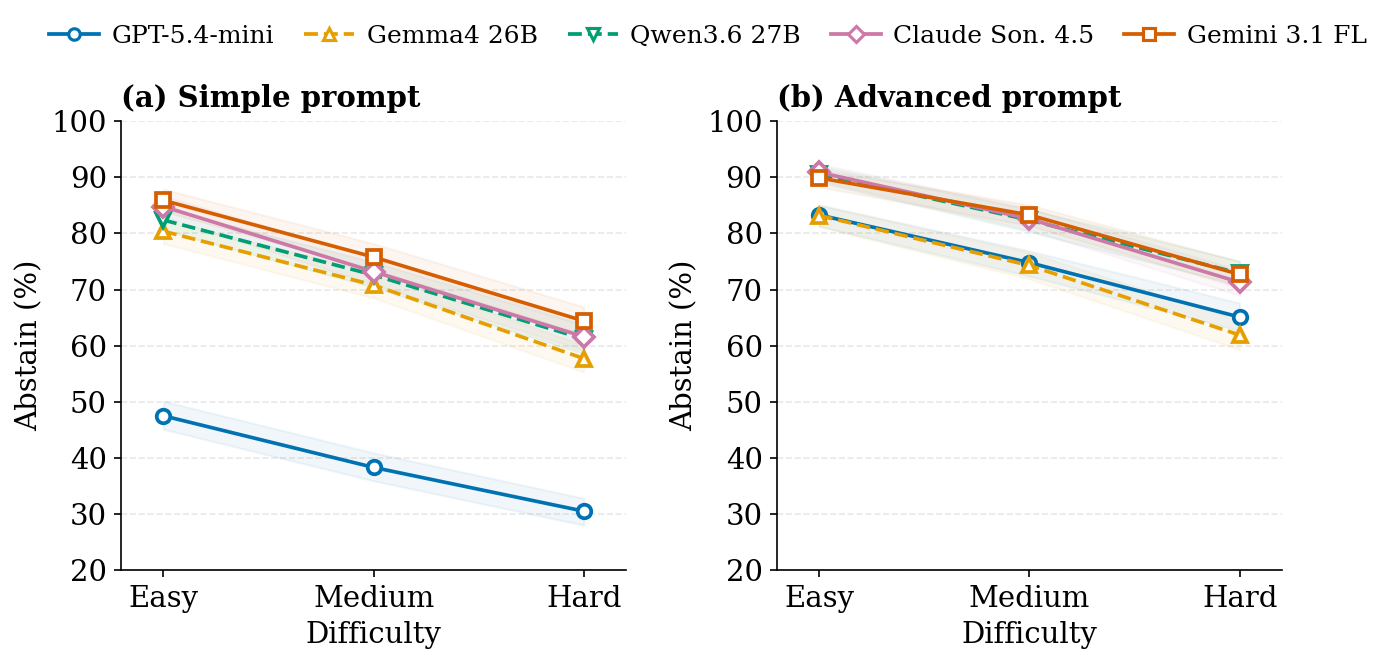

Saved fig3_abstain_by_difficulty.


In [205]:
x_pos    = np.arange(3)
x_labels = [DIFFICULTY_LABELS[d] for d in DIFFICULTY_ORDER]


def _line_panel(ax, df, metric, prompt, ylim, yticks):
    col, col_lo, col_hi = f'{metric}_pct', f'{metric}_lo', f'{metric}_hi'
    sub = df[df['prompt'] == prompt]
    for model in MODEL_ORDER:
        mdf = sub[sub['model_display'] == model].sort_values('difficulty')
        if mdf.empty:
            continue
        c  = MODEL_COLORS[model]
        ls = DISPLAY_LS[model]
        mk = MARKER_SHAPES[model]
        ax.plot(x_pos, mdf[col].values,
                color=c, linestyle=ls, linewidth=1.75,
                marker=mk, markersize=6.5,
                markerfacecolor='white', markeredgewidth=1.8, zorder=4)
        ax.fill_between(x_pos, mdf[col_lo].values, mdf[col_hi].values,
                        color=c, alpha=0.06, zorder=2)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels, fontsize=14)
    ax.set_xlabel('Difficulty', labelpad=4, fontsize=14)
    ax.set_xlim(-0.2, 2.2)
    ax.set_ylim(*ylim)
    ax.set_yticks(yticks)
    ax.tick_params(axis='y', labelsize=14)


def _model_legend_handles():
    handles = []
    for model in MODEL_ORDER:
        h = mlines.Line2D([], [],
                          color=MODEL_COLORS[model],
                          linestyle=DISPLAY_LS[model],
                          linewidth=1.8,
                          marker=MARKER_SHAPES[model],
                          markersize=5.5,
                          markerfacecolor='white',
                          markeredgewidth=1.5,
                          label=MODEL_SHORT[model])
        handles.append(h)
    return handles


fig, (ax_s, ax_a) = plt.subplots(1, 2, figsize=(8.5, 4.4),
                                   gridspec_kw=dict(wspace=0.30))
fig.subplots_adjust(left=0.08, right=0.99, top=0.82, bottom=0.14)

_line_panel(ax_s, tbl_main, 'ABSTAIN', 'simple',   ABSTAIN_YLIM, ABSTAIN_YTICKS)
ax_s.set_ylabel('Abstain (%)', labelpad=4, fontsize=14)
ax_s.set_title('(a) Simple prompt', fontsize=14, fontweight='bold', pad=7, loc='left')

_line_panel(ax_a, tbl_main, 'ABSTAIN', 'advanced',  ABSTAIN_YLIM, ABSTAIN_YTICKS)
ax_a.set_ylabel('Abstain (%)', labelpad=4, fontsize=14)
ax_a.set_title('(b) Advanced prompt', fontsize=14, fontweight='bold', pad=7, loc='left')

fig.legend(handles=_model_legend_handles(), loc='upper center', ncol=5,
           fontsize=12, frameon=False, bbox_to_anchor=(0.54, 1.0),
           handlelength=2.0, handletextpad=0.5, columnspacing=1.2)

fig.savefig(OUT_FIGS / 'fig3_abstain_by_difficulty.pdf', bbox_inches='tight')
fig.savefig(OUT_FIGS / 'fig3_abstain_by_difficulty.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved fig3_abstain_by_difficulty.')


## Incorrect Rate by Difficulty

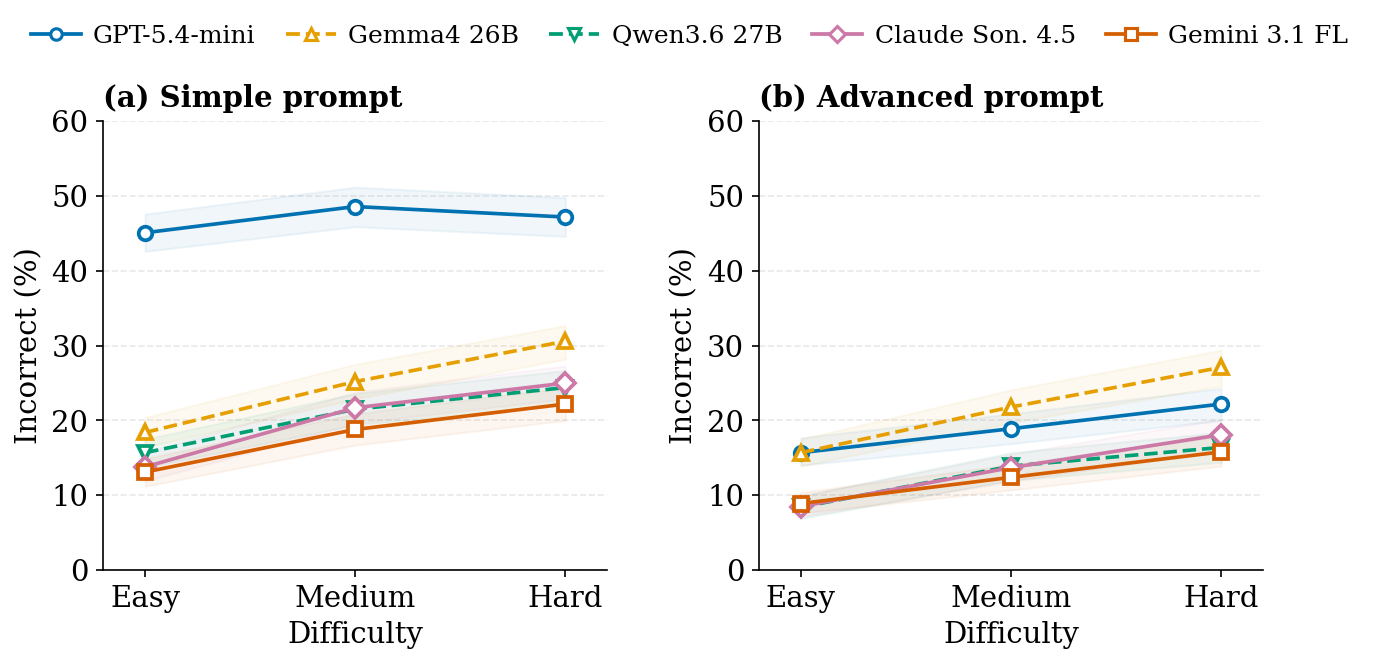

Saved fig4_incorrect_by_difficulty.


In [206]:
fig, (ax_s, ax_a) = plt.subplots(1, 2, figsize=(8.5, 4.4),
                                   gridspec_kw=dict(wspace=0.30))
fig.subplots_adjust(left=0.08, right=0.99, top=0.82, bottom=0.14)

_line_panel(ax_s, tbl_main, 'INCORRECT', 'simple',   INCORRECT_YLIM, INCORRECT_YTICKS)
ax_s.set_ylabel('Incorrect (%)', labelpad=4, fontsize=14)
ax_s.set_title('(a) Simple prompt', fontsize=14, fontweight='bold', pad=7, loc='left')

_line_panel(ax_a, tbl_main, 'INCORRECT', 'advanced',  INCORRECT_YLIM, INCORRECT_YTICKS)
ax_a.set_ylabel('Incorrect (%)', labelpad=4, fontsize=14)
ax_a.set_title('(b) Advanced prompt', fontsize=14, fontweight='bold', pad=7, loc='left')

fig.legend(handles=_model_legend_handles(), loc='upper center', ncol=5,
           fontsize=12, frameon=False, bbox_to_anchor=(0.54, 1.0),
           handlelength=2.0, handletextpad=0.5, columnspacing=1.2)

fig.savefig(OUT_FIGS / 'fig4_incorrect_by_difficulty.pdf', bbox_inches='tight')
fig.savefig(OUT_FIGS / 'fig4_incorrect_by_difficulty.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved fig4_incorrect_by_difficulty.')


## Abstention by Language

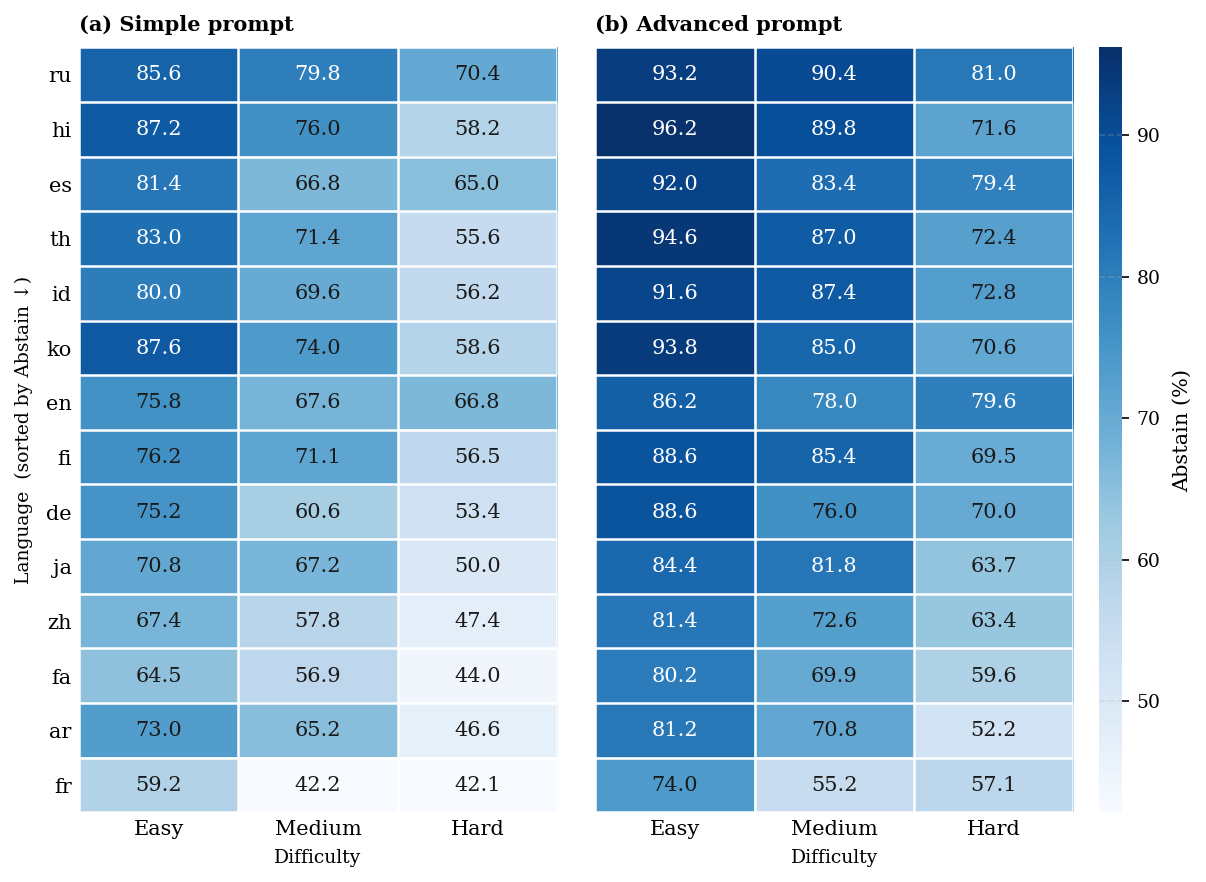

Saved fig5_language_heatmap.


In [207]:
lang_pivot_data = {}
for prompt in ['simple', 'advanced']:
    sub = df_main[df_main['prompt'] == prompt]
    grp = sub.groupby(['language', 'difficulty']).apply(
        lambda g: (g['label'] == 'ABSTAIN').mean() * 100
    ).reset_index(name='ABSTAIN_pct')
    piv = grp.pivot(index='language', columns='difficulty', values='ABSTAIN_pct')[DIFFICULTY_ORDER]
    lang_pivot_data[prompt] = piv

lang_order = lang_pivot_data['advanced'].mean(axis=1).sort_values(ascending=False).index.tolist()
col_labels = [DIFFICULTY_LABELS[d] for d in DIFFICULTY_ORDER]
vmin = min(p.min().min() for p in lang_pivot_data.values())
vmax = max(p.max().max() for p in lang_pivot_data.values())
n_lang = len(lang_order)

fig, axes = plt.subplots(1, 2, figsize=(8.5, 6.0), gridspec_kw=dict(wspace=0.08))
fig.subplots_adjust(left=0.10, right=0.88, top=0.93, bottom=0.08)

for ax, (prompt, panel_letter) in zip(axes, [('simple', 'a'), ('advanced', 'b')]):
    piv = lang_pivot_data[prompt].loc[lang_order].copy()
    piv.columns = col_labels
    im = ax.imshow(piv.values, aspect='auto', cmap='Blues',
                   vmin=vmin, vmax=vmax, interpolation='nearest')
    ax.grid(False)  # disable global grid; cell separators are drawn explicitly below
    for i in range(n_lang):
        for j in range(len(col_labels)):
            val = piv.iloc[i, j]
            tc = 'white' if val > vmin + (vmax - vmin) * 0.65 else '#1a1a1a'
            ax.text(j, i, f'{val:.1f}', ha='center', va='center', fontsize=10, color=tc)
    ax.set_xticks(np.arange(len(col_labels)))
    ax.set_xticklabels(col_labels, fontsize=10)
    ax.set_xlabel('Difficulty', labelpad=5)
    ax.tick_params(length=0)
    ax.set_frame_on(False)
    ax.set_yticks(np.arange(n_lang))
    if prompt == 'simple':
        ax.set_yticklabels(lang_order, fontsize=10)
        ax.set_ylabel('Language  (sorted by Abstain ↓)', labelpad=6)
    else:
        ax.set_yticklabels([])
    ax.set_title(f'({panel_letter}) {prompt.capitalize()} prompt',
                 fontsize=10, fontweight='bold', pad=8, loc='left')
    for x in np.arange(-0.5, len(col_labels), 1):
        ax.axvline(x, color='white', lw=1.2, zorder=3)
    for y in np.arange(-0.5, n_lang, 1):
        ax.axhline(y, color='white', lw=1.2, zorder=3)

cbar_ax = fig.add_axes([0.90, 0.08, 0.018, 0.85])
cb = fig.colorbar(im, cax=cbar_ax)
cb.set_label('Abstain (%)', fontsize=10, labelpad=6)
cb.ax.tick_params(labelsize=9)
cb.outline.set_visible(False)

fig.savefig(OUT_FIGS / 'fig5_language_heatmap.pdf', bbox_inches='tight')
fig.savefig(OUT_FIGS / 'fig5_language_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved fig5_language_heatmap.')

## Incorrect Rate by Language

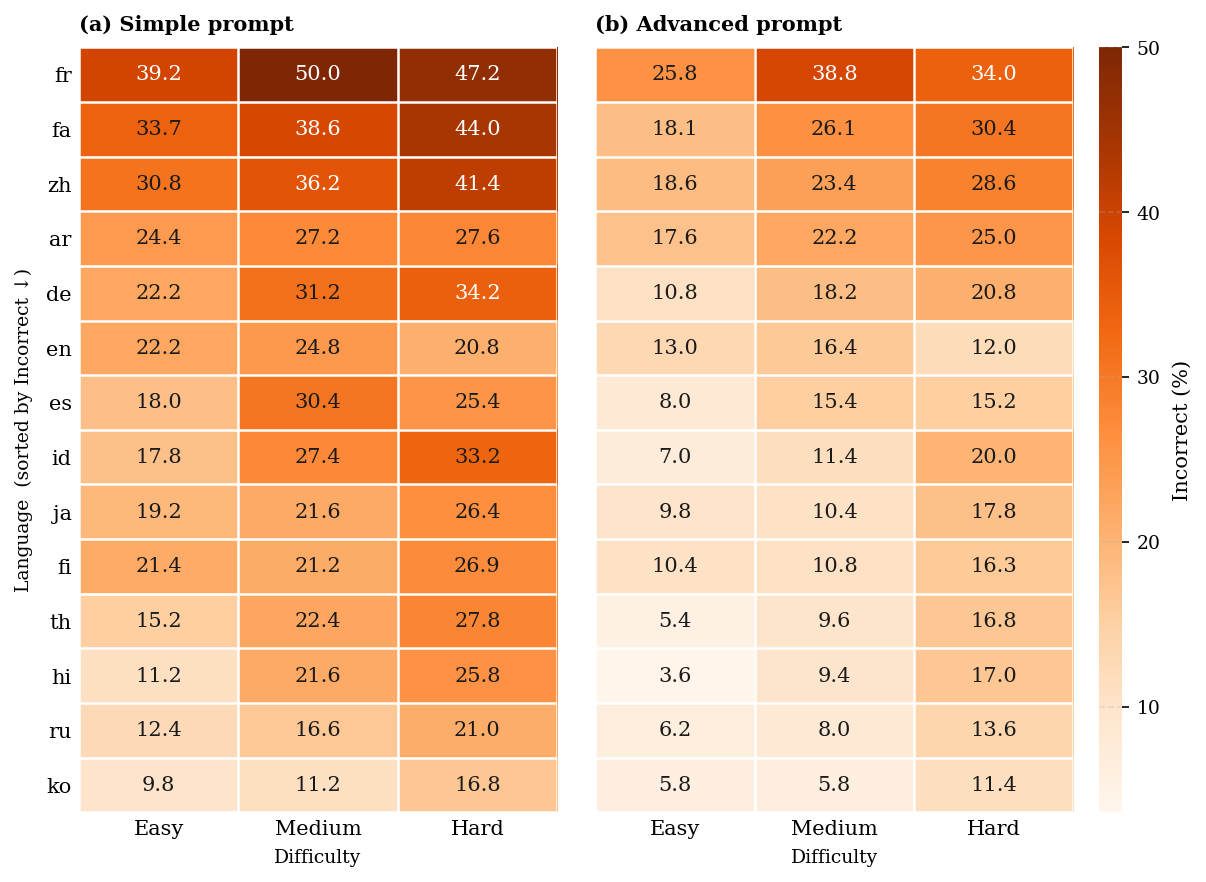

Saved fig5b_language_heatmap_incorrect.


In [208]:
lang_pivot_inc = {}
for prompt in ['simple', 'advanced']:
    sub = df_main[df_main['prompt'] == prompt]
    grp = sub.groupby(['language', 'difficulty']).apply(
        lambda g: (g['label'] == 'INCORRECT').mean() * 100
    ).reset_index(name='INCORRECT_pct')
    piv = grp.pivot(index='language', columns='difficulty', values='INCORRECT_pct')[DIFFICULTY_ORDER]
    lang_pivot_inc[prompt] = piv

lang_order_inc = lang_pivot_inc['advanced'].mean(axis=1).sort_values(ascending=False).index.tolist()
col_labels = [DIFFICULTY_LABELS[d] for d in DIFFICULTY_ORDER]
vmin_inc = min(p.min().min() for p in lang_pivot_inc.values())
vmax_inc = max(p.max().max() for p in lang_pivot_inc.values())
n_lang = len(lang_order_inc)

fig, axes = plt.subplots(1, 2, figsize=(8.5, 6.0), gridspec_kw=dict(wspace=0.08))
fig.subplots_adjust(left=0.10, right=0.88, top=0.93, bottom=0.08)

for ax, (prompt, panel_letter) in zip(axes, [('simple', 'a'), ('advanced', 'b')]):
    piv = lang_pivot_inc[prompt].loc[lang_order_inc].copy()
    piv.columns = col_labels
    im = ax.imshow(piv.values, aspect='auto', cmap='Oranges',
                   vmin=vmin_inc, vmax=vmax_inc, interpolation='nearest')
    ax.grid(False)
    for i in range(n_lang):
        for j in range(len(col_labels)):
            val = piv.iloc[i, j]
            tc = 'white' if val > vmin_inc + (vmax_inc - vmin_inc) * 0.65 else '#1a1a1a'
            ax.text(j, i, f'{val:.1f}', ha='center', va='center', fontsize=10, color=tc)
    ax.set_xticks(np.arange(len(col_labels)))
    ax.set_xticklabels(col_labels, fontsize=10)
    ax.set_xlabel('Difficulty', labelpad=5)
    ax.tick_params(length=0)
    ax.set_frame_on(False)
    ax.set_yticks(np.arange(n_lang))
    if prompt == 'simple':
        ax.set_yticklabels(lang_order_inc, fontsize=10)
        ax.set_ylabel('Language  (sorted by Incorrect ↓)', labelpad=6)
    else:
        ax.set_yticklabels([])
    ax.set_title(f'({panel_letter}) {prompt.capitalize()} prompt',
                 fontsize=10, fontweight='bold', pad=8, loc='left')
    for x in np.arange(-0.5, len(col_labels), 1):
        ax.axvline(x, color='white', lw=1.2, zorder=3)
    for y in np.arange(-0.5, n_lang, 1):
        ax.axhline(y, color='white', lw=1.2, zorder=3)

cbar_ax = fig.add_axes([0.90, 0.08, 0.018, 0.85])
cb = fig.colorbar(im, cax=cbar_ax)
cb.set_label('Incorrect (%)', fontsize=10, labelpad=6)
cb.ax.tick_params(labelsize=9)
cb.outline.set_visible(False)

fig.savefig(OUT_FIGS / 'fig5b_language_heatmap_incorrect.pdf', bbox_inches='tight')
fig.savefig(OUT_FIGS / 'fig5b_language_heatmap_incorrect.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved fig5b_language_heatmap_incorrect.')


## Abstain + Incorrect by Language (combined 2×2)

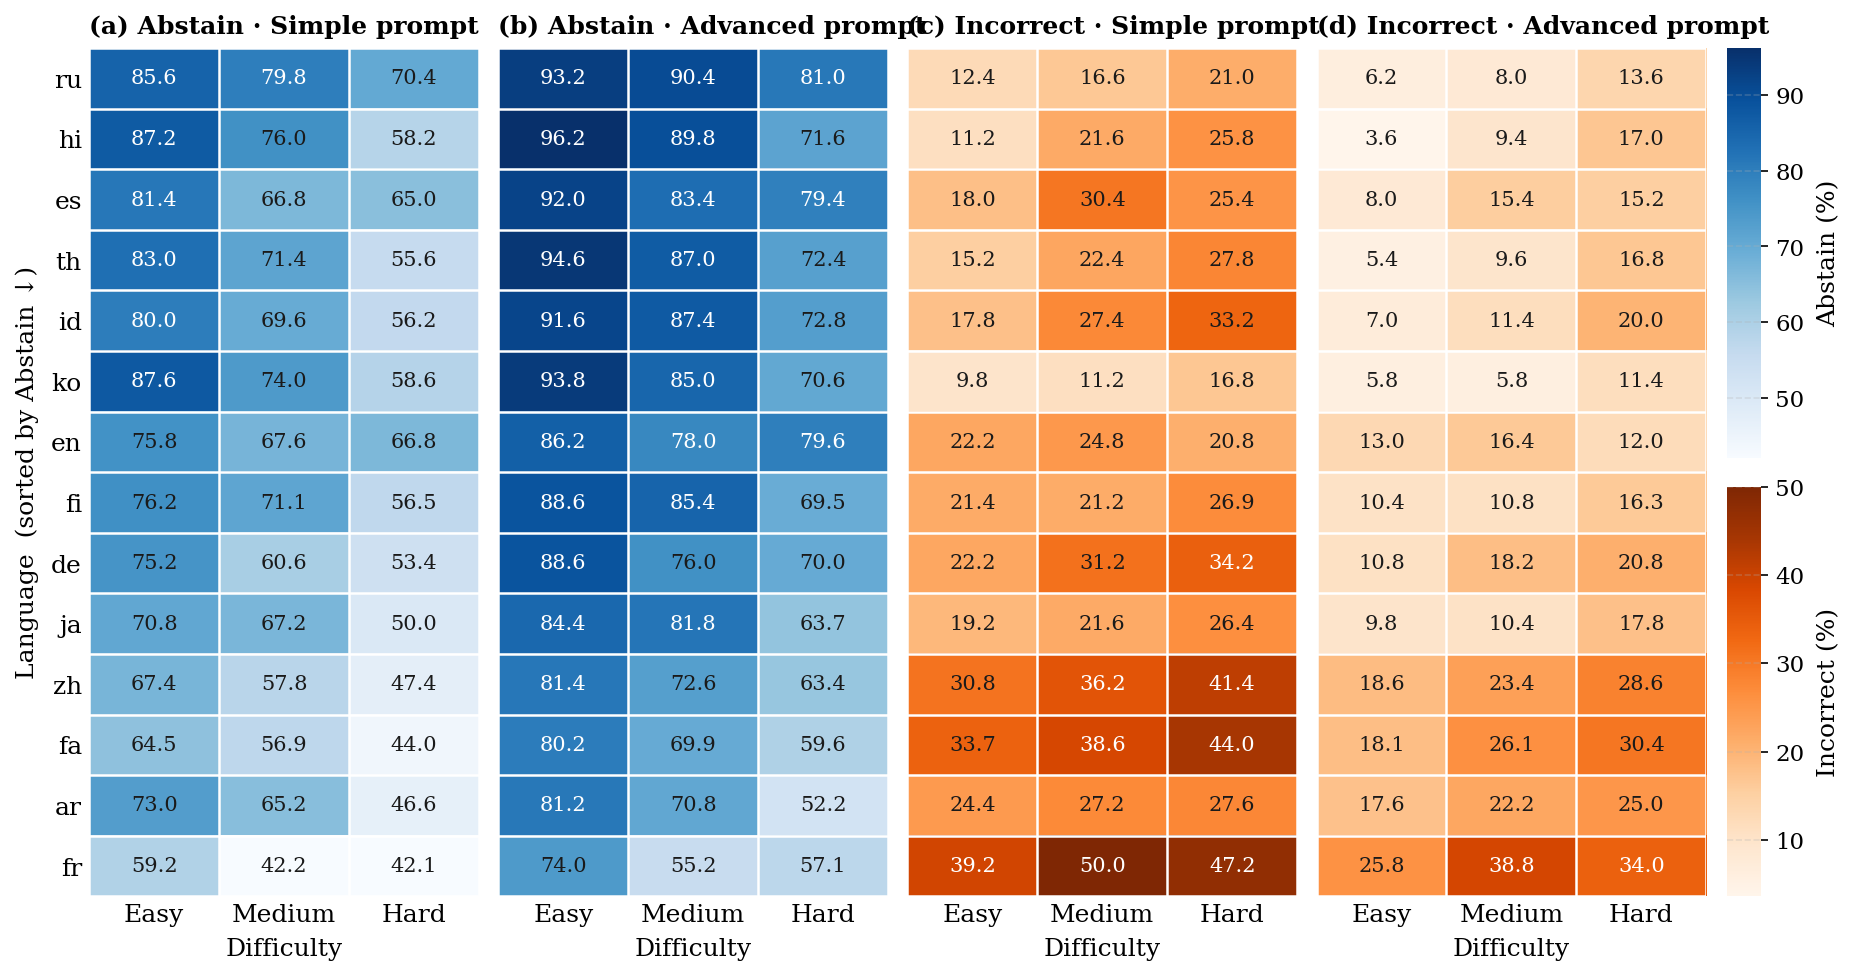

Saved fig5c_language_heatmap_combined.


In [209]:
# Language order: sorted by mean abstain rate on advanced prompt (descending)
lang_order_comb = lang_pivot_data['advanced'].mean(axis=1).sort_values(ascending=False).index.tolist()
col_labels_comb = [DIFFICULTY_LABELS[d] for d in DIFFICULTY_ORDER]
n_lang_comb = len(lang_order_comb)

vmin_abs_c = min(p.min().min() for p in lang_pivot_data.values())
vmax_abs_c = max(p.max().max() for p in lang_pivot_data.values())
vmin_inc_c = min(p.min().min() for p in lang_pivot_inc.values())
vmax_inc_c = max(p.max().max() for p in lang_pivot_inc.values())

# 1×4 grid: (a) Abstain/Simple  (b) Abstain/Advanced  (c) Incorrect/Simple  (d) Incorrect/Advanced
panels = [
    ('a', 'Abstain',   lang_pivot_data, 'Blues',   vmin_abs_c, vmax_abs_c, 'simple',   'Simple prompt'),
    ('b', 'Abstain',   lang_pivot_data, 'Blues',   vmin_abs_c, vmax_abs_c, 'advanced', 'Advanced prompt'),
    ('c', 'Incorrect', lang_pivot_inc,  'Oranges', vmin_inc_c, vmax_inc_c, 'simple',   'Simple prompt'),
    ('d', 'Incorrect', lang_pivot_inc,  'Oranges', vmin_inc_c, vmax_inc_c, 'advanced', 'Advanced prompt'),
]

fig, axes = plt.subplots(1, 4, figsize=(14.0, 6.5),
                          gridspec_kw=dict(wspace=0.05))
fig.subplots_adjust(left=0.10, right=0.87, top=0.94, bottom=0.07)

ims_comb = {}
for ci, (letter, metric_name, pivot_dict, cmap, vmin, vmax, prompt, prompt_label) in enumerate(panels):
    ax = axes[ci]
    piv = pivot_dict[prompt].loc[lang_order_comb].copy()
    piv.columns = col_labels_comb
    im = ax.imshow(piv.values, aspect='auto', cmap=cmap,
                   vmin=vmin, vmax=vmax, interpolation='nearest')
    ims_comb[metric_name] = im
    ax.grid(False)
    for i in range(n_lang_comb):
        for j in range(len(col_labels_comb)):
            val = piv.iloc[i, j]
            tc = 'white' if val > vmin + (vmax - vmin) * 0.65 else '#1a1a1a'
            ax.text(j, i, f'{val:.1f}', ha='center', va='center', fontsize=10, color=tc)
    ax.set_xticks(np.arange(len(col_labels_comb)))
    ax.set_xticklabels(col_labels_comb, fontsize=12)
    ax.set_xlabel('Difficulty', labelpad=5, fontsize=12)
    ax.tick_params(length=0)
    ax.set_frame_on(False)
    ax.set_yticks(np.arange(n_lang_comb))
    if ci == 0:
        ax.set_yticklabels(lang_order_comb, fontsize=12)
        ax.set_ylabel('Language  (sorted by Abstain ↓)', labelpad=6, fontsize=12)
    else:
        ax.set_yticklabels([])
    ax.set_title(f'({letter}) {metric_name} · {prompt_label}',
                 fontsize=12, fontweight='bold', pad=7, loc='left')
    for x in np.arange(-0.5, len(col_labels_comb), 1):
        ax.axvline(x, color='white', lw=1.2, zorder=3)
    for y in np.arange(-0.5, n_lang_comb, 1):
        ax.axhline(y, color='white', lw=1.2, zorder=3)

# Two colorbars stacked on right: top=Abstain, bottom=Incorrect
for (label, metric_name), (bottom, height) in zip(
    [('Abstain (%)', 'Abstain'), ('Incorrect (%)', 'Incorrect')],
    [(0.52, 0.42), (0.07, 0.42)],
):
    cax = fig.add_axes([0.88, bottom, 0.016, height])
    cb  = fig.colorbar(ims_comb[metric_name], cax=cax)
    cb.set_label(label, fontsize=12, labelpad=6)
    cb.ax.tick_params(labelsize=11)
    cb.outline.set_visible(False)

fig.savefig(OUT_FIGS / 'fig5c_language_heatmap_combined.pdf', bbox_inches='tight')
fig.savefig(OUT_FIGS / 'fig5c_language_heatmap_combined.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved fig5c_language_heatmap_combined.')


# Label Composition

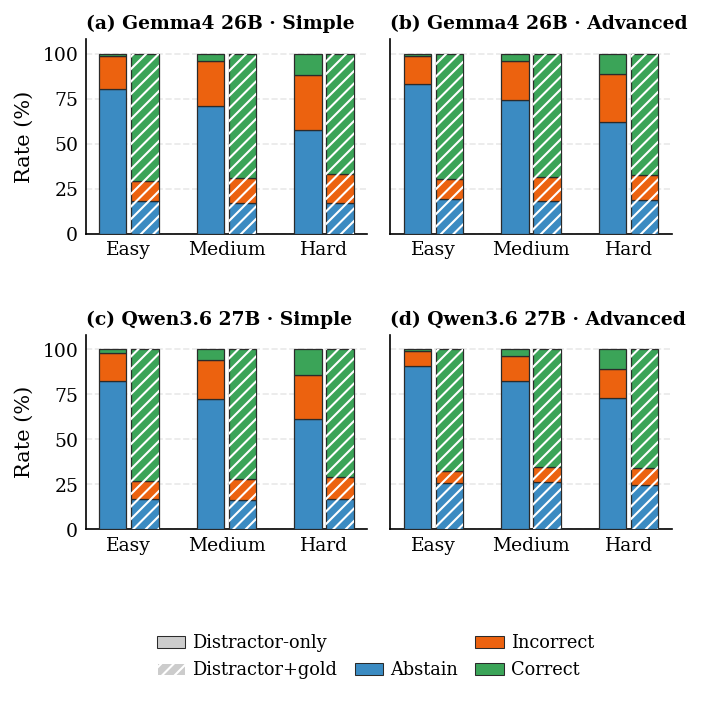

Saved fig6_robustness_stacked.


In [210]:
open_models  = ['gemma4:26b', 'qwen3.6:27b']
metric_cols  = ['ABSTAIN_pct', 'INCORRECT_pct', 'CORRECT_pct']
metric_names = ['Abstain', 'Incorrect', 'Correct']
metric_colors = [LABEL_COLORS['ABSTAIN'], LABEL_COLORS['INCORRECT'], LABEL_COLORS['CORRECT']]

main_open = tbl_main[tbl_main['model_display'].isin(open_models)].copy()
main_open['condition'] = 'distractor-only'
rob_open  = tbl_rob_base.copy()
rob_open['condition']  = 'distractor+gold'
combined = pd.concat([main_open, rob_open], ignore_index=True)
combined['difficulty'] = pd.Categorical(combined['difficulty'], DIFFICULTY_ORDER, ordered=True)

bar_w     = 0.28
inner_gap = 0.05
x_centres = np.arange(3)
x_left    = x_centres - (bar_w + inner_gap) / 2
x_right   = x_centres + (bar_w + inner_gap) / 2
x_by_cond = {'distractor-only': x_left, 'distractor+gold': x_right}

conds = [('distractor-only', ''), ('distractor+gold', '////')]
panel_labels = {(0, 0): 'a', (0, 1): 'b', (1, 0): 'c', (1, 1): 'd'}
model_titles = {'gemma4:26b': 'Gemma4 26B', 'qwen3.6:27b': 'Qwen3.6 27B'}

fig, axes = plt.subplots(2, 2, figsize=(4.6, 4.6), sharey=True,
                          gridspec_kw=dict(hspace=0.52, wspace=0.08))
fig.subplots_adjust(left=0.13, right=0.98, top=0.95, bottom=0.24)

for ri, model in enumerate(open_models):
    for ci, prompt in enumerate(['simple', 'advanced']):
        ax = axes[ri, ci]
        letter = panel_labels[(ri, ci)]

        for cond, hatch in conds:
            xs = x_by_cond[cond]
            for diff_i, diff in enumerate(DIFFICULTY_ORDER):
                row = combined[
                    (combined['model_display'] == model) &
                    (combined['prompt']        == prompt) &
                    (combined['condition']     == cond)   &
                    (combined['difficulty']    == diff)
                ]
                if row.empty:
                    continue
                bottom = 0.0
                for mcol, mc in zip(metric_cols, metric_colors):
                    val = row[mcol].values[0]
                    ax.bar(xs[diff_i], val, width=bar_w, bottom=bottom,
                           color=mc, edgecolor='#2b2b2b', linewidth=0.6, zorder=3)
                    if hatch:
                        ax.bar(xs[diff_i], val, width=bar_w, bottom=bottom,
                               color='none', hatch=hatch, edgecolor='white',
                               linewidth=0, zorder=4)
                    bottom += val

        ax.set_xlim(x_left[0] - bar_w, x_right[-1] + bar_w)
        ax.set_ylim(0, 108)
        ax.set_yticks([0, 25, 50, 75, 100])
        ax.set_yticklabels([0, 25, 50, 75, 100], fontsize=9)
        ax.set_xticks(x_centres)
        ax.set_xticklabels([DIFFICULTY_LABELS[d] for d in DIFFICULTY_ORDER], fontsize=9)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.grid(axis='y', alpha=0.28, linestyle='--', zorder=1)
        ax.tick_params(length=0)
        if ci == 0:
            ax.set_ylabel('Rate (%)', labelpad=4, fontsize=10)
        ax.set_title(f'({letter}) {model_titles[model]} · {prompt.capitalize()}',
                     fontsize=9, fontweight='bold', pad=5, loc='left')

# ── Legend: 2 rows × 3 cols ───────────────────────────────────────────────────
# Row 1: Distractor-only | Distractor+gold | (empty)
# Row 2: Abstain         | Incorrect       | Correct
empty = mpatches.Patch(alpha=0, linewidth=0, label='')
legend_handles = [
    mpatches.Patch(facecolor='#cccccc', edgecolor='#2b2b2b', linewidth=0.5, label='Distractor-only'),
    mpatches.Patch(facecolor='#cccccc', hatch='////', edgecolor='white',  linewidth=0.5, label='Distractor+gold'),
    empty,
    mpatches.Patch(facecolor=metric_colors[0], edgecolor='#2b2b2b', linewidth=0.5, label='Abstain'),
    mpatches.Patch(facecolor=metric_colors[1], edgecolor='#2b2b2b', linewidth=0.5, label='Incorrect'),
    mpatches.Patch(facecolor=metric_colors[2], edgecolor='#2b2b2b', linewidth=0.5, label='Correct'),
]
fig.legend(handles=legend_handles, loc='lower center', ncol=3,
           fontsize=8.5, frameon=False, bbox_to_anchor=(0.55, 0.0),
           handlelength=1.6, handletextpad=0.4, columnspacing=1.0)

fig.savefig(OUT_FIGS / 'fig6_robustness_stacked.pdf', bbox_inches='tight')
fig.savefig(OUT_FIGS / 'fig6_robustness_stacked.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved fig6_robustness_stacked.')
